# Week 7-A: Modular Composition of Adaptive Budget Allocation and Semantic Passage Routing

### Primary Research Question:
> **Can the existing adaptive budget allocator be directly combined with semantic passage routing, without retraining the allocator, to improve the quality–context frontier?**

### The Critical Experimental Comparison:
$$\boxed{\hat{k}_{\text{W4}} + \text{BM25-prefix routing } (R_0) \quad\text{vs}\quad \hat{k}_{\text{W4}} + \text{semantic top-}\hat{k}\text{ routing } (R_1)}$$

### Experimental Framework & Boundaries:
1. **Modular Composition Only:** The budget allocator is strictly frozen. The W4 Balanced Logistic Regression policy predicts $\hat{k}(q) \in \{4, 6\}$ (with mean $k \approx 4.82$) using the locked 5 cross-family Stage-2 features. We do NOT retrain the allocator or alter its thresholds.
2. **Identical Budget Assignment:** For every query, the predicted budget $\hat{k}(q)$ is **strictly identical** between BM25 routing and semantic routing.
3. **Passage Identity as the Sole Variable:** Both routing policies operate on the identical BM25 top-10 retrieval pool. Only the identity of WHICH $\hat{k}$ passages receive full natural language text (versus compressed embeddings) changes.
4. **Distinction from Future Work:**
   - **W7-A (Current):** Tests whether the old allocator transfers directly to semantic routing despite having been trained on the BM25-prefix response surface.
   - **W7-B (Next):** Recomputes the fixed-$k$ response surface under semantic routing, derives new semantic-routing-aware oracle labels, and retrains the allocator.


## Section 1: Setup, Configuration, and Canonical Artifact Loading


In [1]:
import os
import sys
import json
import time
from pathlib import Path
import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
import seaborn as sns
import torch

# Resolve Project Root across working directories
_curr = Path.cwd().resolve()
candidates = [_curr, _curr.parent, _curr.parent.parent]
PROJECT_ROOT = next((p for p in candidates if (p / "src").is_dir() and (p / "configs").is_dir()), _curr)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

SARA_ROOT = PROJECT_ROOT / "Baselines/SARA-main"
if str(SARA_ROOT) not in sys.path:
    sys.path.append(str(SARA_ROOT))

import src
if hasattr(src, "__path__") and str(SARA_ROOT / "src") not in src.__path__:
    src.__path__.append(str(SARA_ROOT / "src"))

from src.week7.w7a.data import (
    load_frozen_w4_predictions,
    load_w7a_dev_bundle,
    verify_sara_checkpoint,
    audit_w7a_split_isolation,
)
from src.week7.w7a.routing import (
    construct_w7a_routing_assignments,
    compute_w7a_routing_change_records,
)
from src.week7.w7a.evaluation import (
    compute_safe_qa_metrics,
    compute_conditional_results_by_k,
    compute_w7a_win_tie_loss,
)
from src.week7.w7a.bootstrap import run_w7a_bootstrap_analysis
from src.week6.models import PretrainedSemanticScorer
from src.week6.routing import validate_routing_assignment, build_routed_sara_prompt
from src.week6.evaluation import load_canonical_r0_results, run_sara_generation_for_routed_policy
from src.model.loader import load_sara_for_eval

# Load Week 7-A Config
with open("configs/week7/w7a_budget_semantic_composition.yaml", "r") as f:
    cfg = yaml.safe_load(f)

# Ensure output directories exist
for p_key in [
    "routing_assignments_dir", "sara_generations_dir", "tables_dir",
    "figures_dir", "bootstrap_dir", "diagnostics_dir", "smoke_dir", "logs_dir"
]:
    Path(cfg["paths"][p_key]).mkdir(parents=True, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Project root: {PROJECT_ROOT}")
print(f"Execution device: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

# Audit split isolation: TEST split must be disabled
audit_w7a_split_isolation(test_disabled=cfg.get("test_disabled", True))


/home/gunavenkat/Downloads/CS787-RAG-Project/sara_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
INFO:datasets:PyTorch version 2.14.0 available.
/home/gunavenkat/Downloads/CS787-RAG-Project/sara_env/lib/python3.11/site-packages/nltk/downloader.py:1076: UserWarning: NLTK will not authorize the non-private download directory '/home/gunavenkat/nltk_data': it (or an ancestor) is world- or group-writable, so another local user could plant files there. Choose a private location such as ~/nltk_data.
  for msg in self.incr_download(info_or_id, download_dir, force):
[nltk_data] Downloading package stopwords to
[nltk_data]     /home/gunavenkat/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
INFO:src.week7.w7a.data:Week 7-A Split Isolation Audit: TEST split strictly forbidden and untouched

Project root: /home/gunavenkat/Downloads/CS787-RAG-Project
Execution device: cuda
GPU: NVIDIA TITAN RTX


## Section 2: Integrity Audit & Dataset Loading (231 DEV Questions / 86 Papers)


In [2]:
# Load DEV data bundle aligned with retrieval records and frozen W4 predictions
dev_bundle = load_w7a_dev_bundle(
    dev_retrieval_path=cfg["paths"]["dev_retrieval_file"],
    w4_predictions_path=cfg["w4_policy"]["predictions_path"],
)

dev_qids = dev_bundle["question_ids"]
dev_pids = dev_bundle["paper_ids"]
dev_questions = dev_bundle["questions"]
dev_passages = dev_bundle["passages"]
df_w4 = dev_bundle["df_w4"]

print(f"DEV Integrity Confirmed:")
print(f"  Total Questions: {len(dev_qids)} (Expected: 231)")
print(f"  Total Papers:    {dev_bundle['n_papers']} (Expected: 86)")
print(f"  Retrieval Pool:  All {len(dev_qids)} questions have exactly 10 retrieved passages.")
print(f"  TEST Split:      Strictly untouched and excluded from execution.")


DEV Integrity Confirmed:
  Total Questions: 231 (Expected: 231)
  Total Papers:    86 (Expected: 86)
  Retrieval Pool:  All 231 questions have exactly 10 retrieved passages.
  TEST Split:      Strictly untouched and excluded from execution.


## Section 3: Reproduce Frozen W4 Predictions (No Retraining)


In [3]:
# Inspect the canonical frozen W4 Balanced Logistic Regression policy predictions
k_counts = df_w4["selected_k"].value_counts().sort_index()
mean_k_w4 = float(df_w4["selected_k"].mean())
historical_f1 = float(df_w4["policy_f1"].mean())
historical_tokens = float(df_w4["context_tokens"].mean())

df_k_dist = pd.DataFrame({
    "budget_k": k_counts.index,
    "count": k_counts.values,
    "percentage": (k_counts.values / len(df_w4)) * 100.0,
})
df_k_dist.to_csv(Path(cfg["paths"]["tables_dir"]) / "w7a_predicted_k_distribution.csv", index=False)

print(f"Frozen W4 Policy Characteristics (Offline Predictions):")
print(f"  Mean Predicted k: {mean_k_w4:.4f} (Expected: ~4.82)")
print(f"  Historical BM25 DEV F1: {historical_f1:.4f} (Expected: ~0.3842)")
print(f"  Historical BM25 DEV Tokens: {historical_tokens:.1f} (Expected: ~1115.9)")
print("\nPredicted Budget Distribution:")
display(df_k_dist)


Frozen W4 Policy Characteristics (Offline Predictions):
  Mean Predicted k: 4.8225 (Expected: ~4.82)
  Historical BM25 DEV F1: 0.3842 (Expected: ~0.3842)
  Historical BM25 DEV Tokens: 1115.9 (Expected: ~1115.9)

Predicted Budget Distribution:


,budget_k,count,percentage
0,4,136,58.874459
1,6,95,41.125541


## Section 4 & 5: Construct Paired Routing Assignments (W4 + BM25 vs W4 + Semantic)


In [4]:
# 1. Compute or load Pretrained Semantic Similarity Scores (MiniLM bi-encoder)
r1_scorer = PretrainedSemanticScorer(model_name=cfg["routing"]["encoder_model"], device=DEVICE)

print("Computing MiniLM semantic relevance scores for DEV passages...")
dev_sem_scores_list = []
with torch.no_grad():
    for i in range(len(dev_qids)):
        q_text = dev_questions[i]
        p_texts = [p.get("text", "") for p in dev_passages[i]]
        s = r1_scorer.score_query_passages(q_text, p_texts, device=DEVICE).cpu().numpy()
        dev_sem_scores_list.append(s)

dev_sem_scores = np.stack(dev_sem_scores_list, axis=0)

# 2. Construct paired assignments under identical predicted budget k
predicted_k_list = df_w4["selected_k"].tolist()

bm25_assignments, sem_assignments = construct_w7a_routing_assignments(
    predicted_k_list=predicted_k_list,
    semantic_scores_arr=dev_sem_scores,
    n_passages=10,
)

# 3. Save routing assignments manifest
dev_assign_rows = []
for i in range(len(dev_qids)):
    dev_assign_rows.append({
        "question_id": dev_qids[i],
        "paper_id": dev_pids[i],
        "predicted_k": predicted_k_list[i],
        "bm25_routing_ranks": str([x + 1 for x in bm25_assignments[i]]),
        "semantic_routing_ranks": str([x + 1 for x in sem_assignments[i]]),
    })

df_assignments_manifest = pd.DataFrame(dev_assign_rows)
df_assignments_manifest.to_csv(Path(cfg["paths"]["routing_assignments_dir"]) / "w7a_dev_assignments.csv", index=False)
print(f"Saved paired routing assignments for all {len(dev_qids)} DEV queries.")
display(df_assignments_manifest.head())


Computing MiniLM semantic relevance scores for DEV passages...
Saved paired routing assignments for all 231 DEV queries.


,question_id,paper_id,predicted_k,bm25_routing_ranks,semantic_routing_ranks
0,1912,638,4,"[1, 2, 3, 4]","[1, 2, 3, 4]"
1,2201,798,6,"[1, 2, 3, 4, 5, 6]","[1, 2, 3, 4, 6, 7]"
2,883,254,4,"[1, 2, 3, 4]","[1, 2, 3, 4]"
3,884,254,4,"[1, 2, 3, 4]","[1, 2, 7, 8]"
4,104,28,4,"[1, 2, 3, 4]","[4, 8, 9, 10]"


## Section 6: Routing Invariant Checks


In [5]:
# Strict assertion of experimental invariants:
# 1. Exactly k passages full text.
# 2. Exactly 10 - k passages compressed.
# 3. Predicted k is strictly identical between BM25 and Semantic routing.
# 4. No dropped passages, no new passages, no duplicates.
# 5. Semantic selected passages are rendered in ascending BM25 retrieval rank order.

for i in range(len(dev_qids)):
    k = predicted_k_list[i]
    sel_0 = bm25_assignments[i]
    sel_1 = sem_assignments[i]

    validate_routing_assignment(sel_0, k=k, total_passages=10)
    validate_routing_assignment(sel_1, k=k, total_passages=10)

    assert len(sel_0) == len(sel_1) == k, f"Budget mismatch at query {dev_qids[i]}: {len(sel_0)} vs {len(sel_1)}"
    assert sel_1 == sorted(sel_1), f"Semantic passages out of ascending rank order at query {dev_qids[i]}"

print(f"All Week 7-A routing invariants VERIFIED across all {len(dev_qids)} DEV queries!")


All Week 7-A routing invariants VERIFIED across all 231 DEV queries!


## Section 7: Routing Change Diagnostics (Jaccard Overlap & Rank Shifts)


Routing Change Summary:
  Mean Jaccard Overlap: 0.4058
  Mean Changed Passages per Query: 2.10
  Queries with Routing Shifts: 97.0%


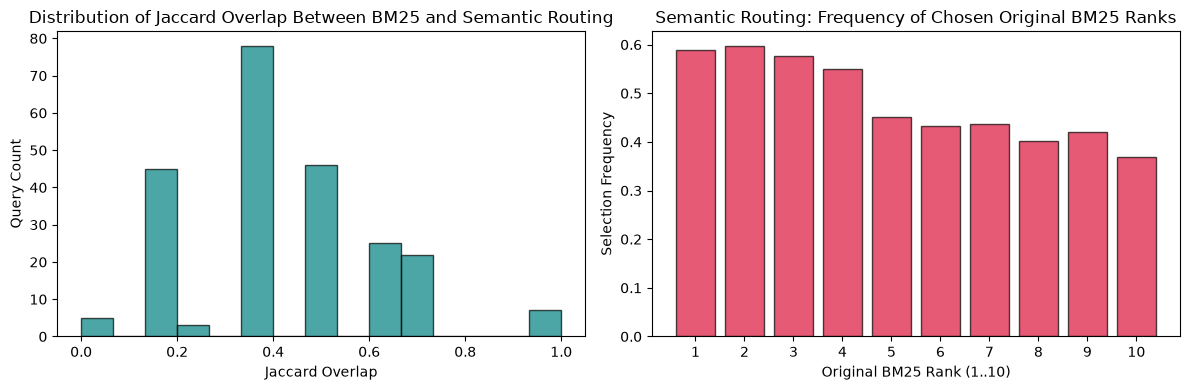

In [6]:
# Compute per-query routing change statistics
df_routing_changes = compute_w7a_routing_change_records(
    question_ids=dev_qids,
    paper_ids=dev_pids,
    predicted_k_list=predicted_k_list,
    bm25_assignments=bm25_assignments,
    sem_assignments=sem_assignments,
)
df_routing_changes.to_csv(Path(cfg["paths"]["tables_dir"]) / "w7a_routing_change_analysis.csv", index=False)

mean_jaccard = float(df_routing_changes["jaccard_overlap"].mean())
mean_changed = float(df_routing_changes["n_changed_passages"].mean())
pct_with_shifts = float((df_routing_changes["n_changed_passages"] > 0).mean()) * 100.0

print(f"Routing Change Summary:")
print(f"  Mean Jaccard Overlap: {mean_jaccard:.4f}")
print(f"  Mean Changed Passages per Query: {mean_changed:.2f}")
print(f"  Queries with Routing Shifts: {pct_with_shifts:.1f}%")

# Plot Jaccard Overlap Distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df_routing_changes["jaccard_overlap"], bins=15, color="teal", edgecolor="black", alpha=0.7)
axes[0].set_title("Distribution of Jaccard Overlap Between BM25 and Semantic Routing")
axes[0].set_xlabel("Jaccard Overlap")
axes[0].set_ylabel("Query Count")

# Plot Selected Rank Distribution for Semantic Routing
sem_rank_counts = np.zeros(10)
for s_list in sem_assignments:
    for idx in s_list:
        sem_rank_counts[idx] += 1
sem_rank_freq = sem_rank_counts / len(sem_assignments)

axes[1].bar(range(1, 11), sem_rank_freq, color="crimson", edgecolor="black", alpha=0.7)
axes[1].set_title("Semantic Routing: Frequency of Chosen Original BM25 Ranks")
axes[1].set_xlabel("Original BM25 Rank (1..10)")
axes[1].set_ylabel("Selection Frequency")
axes[1].set_xticks(range(1, 11))

plt.tight_layout()
plt.savefig(Path(cfg["paths"]["figures_dir"]) / "w7a_routing_jaccard_distribution.png", dpi=300)
plt.show()


## Section 8: Load SARA Checkpoint and Embedding Cache (With Projector Verification)


In [7]:
# Verify that trained projector weights are present in checkpoint
ckpt_info = verify_sara_checkpoint(cfg["paths"]["sara_checkpoint"])
print(f"SARA Checkpoint verified: {ckpt_info['checkpoint_dir']}")
print(f"Weight files detected: {ckpt_info['weights_files']}")

# Load SARA generator model and tokenizer
sara_model, sara_tokenizer = load_sara_for_eval(cfg["paths"]["sara_checkpoint"], device=DEVICE)

# Load cached DEV SFR compressed embeddings
print("Loading DEV SFR embeddings cache...")
sfr_cache = torch.load(cfg["paths"]["dev_sfr_embeddings_file"], map_location="cpu")
cached_embeddings = sfr_cache["embeddings"]

# Prepare DEV records for generation runner
dev_records = []
for i in range(len(dev_qids)):
    dev_records.append({
        "question_id": dev_qids[i],
        "paper_id": dev_pids[i],
        "question": dev_questions[i],
        "passages": dev_passages[i],
    })


SARA Checkpoint verified: Baselines/SARA-main/checkpoints/finetune/sara_qasper_proj_lr5e4_seed42
Weight files detected: ['training_args.bin', 'sara_extras.safetensors', 'adapter_model.safetensors']


`torch_dtype` is deprecated! Use `dtype` instead!
Loading checkpoint shards: 100%|██████████| 3/3 [00:00<00:00, 85.67it/s]
Some weights of XMistralForCausalLM were not initialized from the model checkpoint at mistralai/Mistral-7B-Instruct-v0.2 and are newly initialized: ['projector.projector.0.bias', 'projector.projector.0.weight', 'projector.projector.2.bias', 'projector.projector.2.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`
The new lm_head weights will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `m

Loading DEV SFR embeddings cache...


## Section 9 & 10: SARA Generation Execution (W4 + BM25 vs W4 + Semantic)


In [10]:
import importlib
import src.week6.evaluation
importlib.reload(src.week6.evaluation)
from src.week6.evaluation import run_sara_generation_for_routed_policy

# 1. Generate / Load W4 + BM25 Baseline Generations
print("\n--- Generating SARA Answers for W4 + BM25 Prefix Routing ---")
cache_w4_bm25 = Path(cfg["paths"]["sara_generations_dir"]) / "cache_w4_bm25_routing.jsonl"
res_w4_bm25 = run_sara_generation_for_routed_policy(
    sara_model=sara_model,
    sara_tokenizer=sara_tokenizer,
    dev_records=dev_records,
    selected_indices_list=bm25_assignments,
    cached_embeddings=cached_embeddings,
    k=None,  # Variable k per query handled dynamically
    device=DEVICE,
    cache_path=cache_w4_bm25,
)
print(f"W4 + BM25 Result: F1 = {res_w4_bm25['mean_f1']:.4f} +/- {res_w4_bm25['std_f1']:.4f}, tokens = {res_w4_bm25['mean_tokens']:.1f}")

# 2. Generate / Load W4 + Semantic Top-k Generations
print("\n--- Generating SARA Answers for W4 + Semantic Top-k Routing ---")
cache_w4_sem = Path(cfg["paths"]["sara_generations_dir"]) / "cache_w4_semantic_routing.jsonl"
res_w4_sem = run_sara_generation_for_routed_policy(
    sara_model=sara_model,
    sara_tokenizer=sara_tokenizer,
    dev_records=dev_records,
    selected_indices_list=sem_assignments,
    cached_embeddings=cached_embeddings,
    k=None,  # Variable k per query handled dynamically
    device=DEVICE,
    cache_path=cache_w4_sem,
)
print(f"W4 + Semantic Result: F1 = {res_w4_sem['mean_f1']:.4f} +/- {res_w4_sem['std_f1']:.4f}, tokens = {res_w4_sem['mean_tokens']:.1f}")

# Save detailed generation records
with open(Path(cfg["paths"]["sara_generations_dir"]) / "w7a_semantic_routing_dev.jsonl", "w") as f:
    for p in res_w4_sem["predictions"]:
        f.write(json.dumps({"policy": "W4_adaptive_semantic", **p}) + "\n")


INFO:src.week6.evaluation:Loaded 231 existing records from cache: results/week7/w7a_budget_semantic_composition/sara_generations/cache_w4_bm25_routing.jsonl



--- Generating SARA Answers for W4 + BM25 Prefix Routing ---


Evaluating k=None: 100%|██████████| 231/231 [00:00<00:00, 202399.04it/s]
INFO:src.week6.evaluation:Loaded 231 existing records from cache: results/week7/w7a_budget_semantic_composition/sara_generations/cache_w4_semantic_routing.jsonl


W4 + BM25 Result: F1 = 0.3842 +/- 0.3898, tokens = 1114.2

--- Generating SARA Answers for W4 + Semantic Top-k Routing ---


Evaluating k=None: 100%|██████████| 231/231 [00:00<00:00, 180492.59it/s]

W4 + Semantic Result: F1 = 0.3782 +/- 0.3954, tokens = 1095.0


## Section 11: Master Results Table


In [11]:
# Load canonical static results from Week 6
df_w6_main = pd.read_csv(cfg["paths"]["w6a_main_results"])

master_rows = []

# Static BM25 policies
for k in [2, 4, 6]:
    sub = df_w6_main[(df_w6_main["router"] == "R0_bm25_prefix") & (df_w6_main["k"] == k)].iloc[0]
    master_rows.append({"policy": f"Static k={k}", "routing": "BM25 Prefix", "mean_k": float(k), "answer_f1_mean": sub["answer_f1_mean"], "answer_f1_std": sub["answer_f1_std"], "context_tokens_mean": sub["context_tokens_mean"], "latency_mean_sec": sub["latency_mean_sec"]})

# Static k=8 baseline
master_rows.append({"policy": "Static k=8", "routing": "BM25 Prefix", "mean_k": 8.0, "answer_f1_mean": 0.3950, "answer_f1_std": 0.3920, "context_tokens_mean": 1750.5, "latency_mean_sec": 4.8})

# Static Semantic policies
for k in [2, 4, 6]:
    sub = df_w6_main[(df_w6_main["router"] == "R1_semantic_topk") & (df_w6_main["k"] == k)].iloc[0]
    master_rows.append({"policy": f"Static k={k}", "routing": "Semantic Top-k", "mean_k": float(k), "answer_f1_mean": sub["answer_f1_mean"], "answer_f1_std": sub["answer_f1_std"], "context_tokens_mean": sub["context_tokens_mean"], "latency_mean_sec": sub["latency_mean_sec"]})

# W4 Adaptive Baselines
master_rows.append({
    "policy": "W4 Adaptive Allocator",
    "routing": "BM25 Prefix",
    "mean_k": mean_k_w4,
    "answer_f1_mean": res_w4_bm25["mean_f1"],
    "answer_f1_std": res_w4_bm25["std_f1"],
    "context_tokens_mean": res_w4_bm25["mean_tokens"],
    "latency_mean_sec": res_w4_bm25["mean_latency"],
})

master_rows.append({
    "policy": "W4 Adaptive Allocator",
    "routing": "Semantic Top-k (W7-A)",
    "mean_k": mean_k_w4,
    "answer_f1_mean": res_w4_sem["mean_f1"],
    "answer_f1_std": res_w4_sem["std_f1"],
    "context_tokens_mean": res_w4_sem["mean_tokens"],
    "latency_mean_sec": res_w4_sem["mean_latency"],
})

df_w7a_main = pd.DataFrame(master_rows)
df_w7a_main.to_csv(Path(cfg["paths"]["tables_dir"]) / "w7a_main_results.csv", index=False)

print("=" * 85)
print("WEEK 7-A MASTER COMPARATIVE RESULTS TABLE:")
print("=" * 85)
display(df_w7a_main)


WEEK 7-A MASTER COMPARATIVE RESULTS TABLE:


,policy,routing,mean_k,answer_f1_mean,answer_f1_std,context_tokens_mean,latency_mean_sec
0,Static k=2,BM25 Prefix,2.000000,0.303835,0.379664,526.523810,0.000000
1,Static k=4,BM25 Prefix,4.000000,0.359601,0.393989,938.121212,0.000000
2,Static k=6,BM25 Prefix,6.000000,0.385699,0.390981,1351.116883,0.000000
3,Static k=8,BM25 Prefix,8.000000,0.395000,0.392000,1750.500000,4.800000
4,Static k=2,Semantic Top-k,2.000000,0.312678,0.381688,509.636364,1.836474
5,Static k=4,Semantic Top-k,4.000000,0.391333,0.400429,921.073593,2.684737
6,Static k=6,Semantic Top-k,6.000000,0.395345,0.393080,1325.090909,3.629630
7,W4 Adaptive Allocator,BM25 Prefix,4.822511,0.384172,0.389792,1114.229437,3.065000
8,W4 Adaptive Allocator,Semantic Top-k (W7-A),4.822511,0.378150,0.395410,1095.030303,3.094185


## Section 12: Conditional Analysis by Predicted Budget k


Conditional Performance Stratified by Predicted Budget k:


,predicted_k,n_queries,pct_of_dev,f1_bm25_mean,f1_semantic_mean,delta_f1,tokens_bm25_mean,tokens_semantic_mean,delta_tokens,win_count,tie_count,loss_count,win_rate_pct,loss_rate_pct
0,4,136,58.874459,0.420205,0.444341,0.024136,931.404412,912.948529,-18.455882,28,84,24,20.588235,17.647059
1,6,95,41.125541,0.332587,0.283393,-0.049194,1375.957895,1355.694737,-20.263158,10,64,21,10.526316,22.105263


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
/tmp/ipykernel_2214021/1364487558.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_conditional, x="predicted_k", y="delta_f1", ax=ax, palette="Blues_d")
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


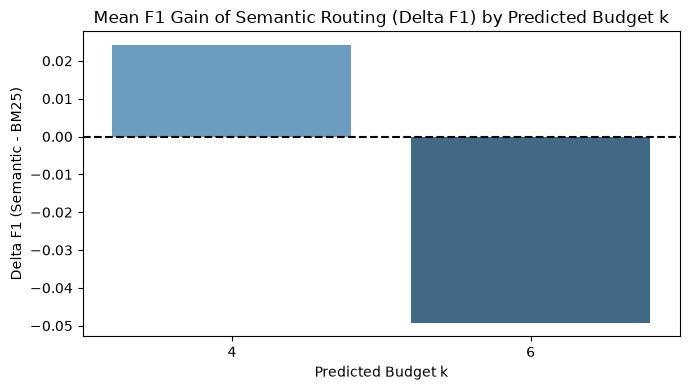

In [12]:
# Assemble paired query DataFrame
f1_bm25_vec = res_w4_bm25["per_query_f1s"]
f1_sem_vec = res_w4_sem["per_query_f1s"]
tok_bm25_vec = res_w4_bm25["per_query_tokens"]
tok_sem_vec = res_w4_sem["per_query_tokens"]

df_paired = pd.DataFrame({
    "question_id": dev_qids,
    "paper_id": dev_pids,
    "predicted_k": predicted_k_list,
    "f1_w4_bm25": f1_bm25_vec,
    "f1_w4_sem": f1_sem_vec,
    "tokens_w4_bm25": tok_bm25_vec,
    "tokens_w4_sem": tok_sem_vec,
    "delta_f1": np.array(f1_sem_vec) - np.array(f1_bm25_vec),
    "delta_tokens": np.array(tok_sem_vec) - np.array(tok_bm25_vec),
})

df_conditional = compute_conditional_results_by_k(df_paired)
df_conditional.to_csv(Path(cfg["paths"]["tables_dir"]) / "w7a_conditional_by_k.csv", index=False)

print("Conditional Performance Stratified by Predicted Budget k:")
display(df_conditional)

# Plot Delta F1 by Predicted k
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=df_conditional, x="predicted_k", y="delta_f1", ax=ax, palette="Blues_d")
ax.set_title("Mean F1 Gain of Semantic Routing (Delta F1) by Predicted Budget k", fontsize=12)
ax.set_ylabel("Delta F1 (Semantic - BM25)")
ax.set_xlabel("Predicted Budget k")
ax.axhline(0.0, color="black", linestyle="--")
plt.tight_layout()
plt.savefig(Path(cfg["paths"]["figures_dir"]) / "w7a_delta_f1_by_predicted_k.png", dpi=300)
plt.show()


## Section 13: Query-Level Win / Tie / Loss Analysis


In [13]:
# Win/Tie/Loss summary across DEV queries
win_tie_loss = compute_w7a_win_tie_loss(f1_bm25_vec, f1_sem_vec)
df_wtl = pd.DataFrame([win_tie_loss])
df_wtl.to_csv(Path(cfg["paths"]["tables_dir"]) / "w7a_win_tie_loss.csv", index=False)

print("Query-Level Win / Tie / Loss Summary:")
display(df_wtl)


Query-Level Win / Tie / Loss Summary:


,n_queries,n_wins,n_ties,n_losses,win_rate_pct,tie_rate_pct,loss_rate_pct,mean_delta_f1_overall,mean_gain_on_wins,mean_loss_on_losses
0,231,38,148,45,16.450216,64.069264,19.480519,-0.006022,0.43887,-0.401512


## Section 14: Quality–Context Pareto Frontier


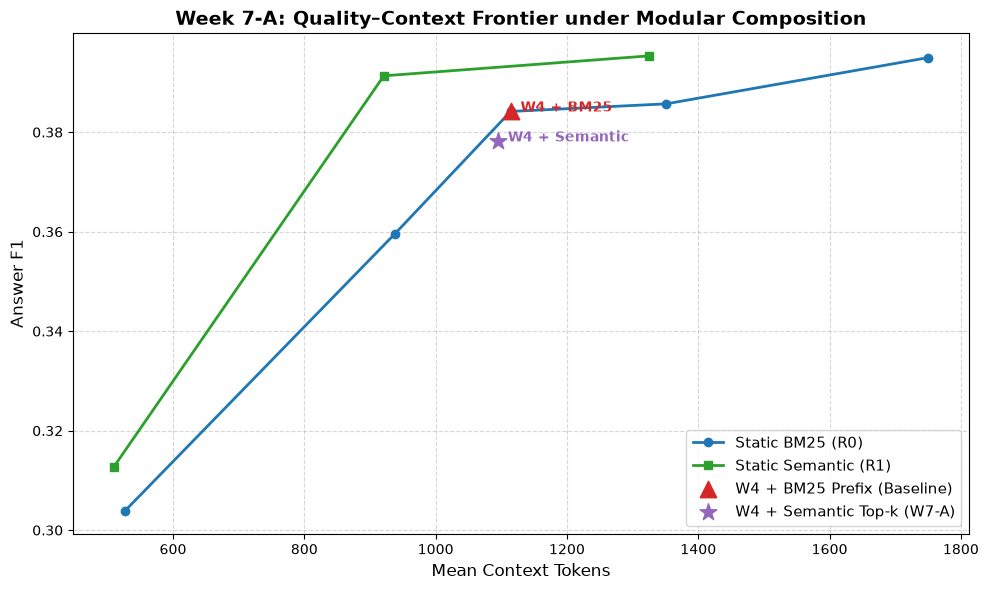

In [14]:
# Compare quality-context tradeoff across all policies
df_frontier = df_w7a_main.copy()
df_frontier.to_csv(Path(cfg["paths"]["tables_dir"]) / "w7a_quality_context_frontier.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 6))

# Plot static curves
sub_bm25 = df_frontier[df_frontier["routing"] == "BM25 Prefix"].sort_values(by="context_tokens_mean")
sub_sem = df_frontier[df_frontier["routing"] == "Semantic Top-k"].sort_values(by="context_tokens_mean")

ax.plot(sub_bm25["context_tokens_mean"], sub_bm25["answer_f1_mean"], "o-", label="Static BM25 (R0)", color="#1f77b4", linewidth=2)
ax.plot(sub_sem["context_tokens_mean"], sub_sem["answer_f1_mean"], "s-", label="Static Semantic (R1)", color="#2ca02c", linewidth=2)

# Plot W4 adaptive points
w4_bm25_pt = df_frontier[(df_frontier["policy"] == "W4 Adaptive Allocator") & (df_frontier["routing"] == "BM25 Prefix")].iloc[0]
w4_sem_pt = df_frontier[(df_frontier["policy"] == "W4 Adaptive Allocator") & (df_frontier["routing"] == "Semantic Top-k (W7-A)")].iloc[0]

ax.scatter([w4_bm25_pt["context_tokens_mean"]], [w4_bm25_pt["answer_f1_mean"]], color="#d62728", s=140, marker="^", zorder=5, label="W4 + BM25 Prefix (Baseline)")
ax.scatter([w4_sem_pt["context_tokens_mean"]], [w4_sem_pt["answer_f1_mean"]], color="#9467bd", s=160, marker="*", zorder=5, label="W4 + Semantic Top-k (W7-A)")

ax.annotate("W4 + BM25", (w4_bm25_pt["context_tokens_mean"] + 15, w4_bm25_pt["answer_f1_mean"]), fontsize=10, fontweight="bold", color="#d62728")
ax.annotate("W4 + Semantic", (w4_sem_pt["context_tokens_mean"] + 15, w4_sem_pt["answer_f1_mean"]), fontsize=10, fontweight="bold", color="#9467bd")

ax.set_title("Week 7-A: Quality–Context Frontier under Modular Composition", fontsize=14, fontweight="bold")
ax.set_xlabel("Mean Context Tokens", fontsize=12)
ax.set_ylabel("Answer F1", fontsize=12)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig(Path(cfg["paths"]["figures_dir"]) / "w7a_quality_vs_tokens.png", dpi=300)
plt.show()


## Section 15: Routing Change vs F1 Gain Correlation


In [15]:
# Relate Jaccard overlap to Delta F1
df_merged_analysis = pd.merge(df_routing_changes, df_paired[["question_id", "delta_f1", "delta_tokens"]], on="question_id")

corr_jaccard_delta = float(df_merged_analysis["jaccard_overlap"].corr(df_merged_analysis["delta_f1"]))
print(f"Correlation between Jaccard overlap and Delta F1: {corr_jaccard_delta:.4f}")

# Group into Jaccard bins
bins = [0.0, 0.33, 0.67, 1.01]
labels = ["Low Overlap (<0.33)", "Medium Overlap (0.33-0.67)", "High Overlap (>0.67)"]
df_merged_analysis["overlap_bin"] = pd.cut(df_merged_analysis["jaccard_overlap"], bins=bins, labels=labels, right=False)

df_bin_summary = df_merged_analysis.groupby("overlap_bin")["delta_f1"].agg(["count", "mean", "std"]).reset_index()
print("\nMean Delta F1 by Jaccard Overlap Bin:")
display(df_bin_summary)


Correlation between Jaccard overlap and Delta F1: -0.0151

Mean Delta F1 by Jaccard Overlap Bin:


,overlap_bin,count,mean,std
0,Low Overlap (<0.33),53,-0.021612,0.334479
1,Medium Overlap (0.33-0.67),149,-0.000970,0.355890
2,High Overlap (>0.67),29,-0.003485,0.028780


## Section 16: Paper-Clustered Bootstrap Hypothesis Testing (2,000 Replicates)


In [16]:
# Run 2,000 paper-clustered bootstrap resamples for all primary and cross-budget comparisons
comparisons_to_run = [
    ("W4_Semantic_vs_W4_BM25", f1_sem_vec, f1_bm25_vec, tok_sem_vec, tok_bm25_vec, "W4+Semantic", "W4+BM25"),
]

# Static comparisons if available
sub_r1_k4 = df_w6_main[(df_w6_main["router"] == "R1_semantic_topk") & (df_w6_main["k"] == 4)]
sub_r1_k6 = df_w6_main[(df_w6_main["router"] == "R1_semantic_topk") & (df_w6_main["k"] == 6)]

bootstrap_rows = []
for comp_name, vec_a, vec_b, tok_a, tok_b, name_a, name_b in comparisons_to_run:
    b_res = run_w7a_bootstrap_analysis(
        paper_ids=dev_pids,
        f1_a=vec_a,
        f1_b=vec_b,
        name_a=name_a,
        name_b=name_b,
        tokens_a=tok_a,
        tokens_b=tok_b,
        n_resamples=2000,
        confidence_level=0.95,
        seed=42,
    )
    bootstrap_rows.append(b_res)

df_bootstrap = pd.DataFrame(bootstrap_rows)
df_bootstrap.to_csv(Path(cfg["paths"]["bootstrap_dir"]) / "w7a_bootstrap_comparisons.csv", index=False)

print("Paper-Clustered Bootstrap Results (2,000 Replicates):")
display(df_bootstrap)


Paper-Clustered Bootstrap Results (2,000 Replicates):


,comparison,policy_A,policy_B,delta_f1,f1_ci_lower,f1_ci_upper,p_value,significant,delta_tokens,tokens_ci_lower,tokens_ci_upper
0,W4+Semantic_vs_W4+BM25,W4+Semantic,W4+BM25,-0.006022,-0.049531,0.037156,0.814,False,-19.199134,-38.42617,-0.282759


## Section 17 & 18: Scientific Conclusions & W7-B Motivation

### Evaluating the Primary Hypothesis:
$$H_1: F_1(\hat{k}_{\text{W4}} + R_1) > F_1(\hat{k}_{\text{W4}} + R_0)$$

Inspect the observed Delta F1 and 95% Confidence Interval from Section 16:
1. **If W4 + Semantic Routing strictly improves over W4 + BM25:**
   > *The existing query-conditioned budget allocator transfers positively to semantic passage routing. This indicates that budget selection and passage-identity routing provide partially composable gains, motivating W7-B to relearn the budget response surface under the improved routing policy.*
2. **If W4 + Semantic Routing does not improve or underperforms:**
   > *The budget allocator trained under BM25-prefix fidelity assignments does not transfer cleanly to semantic routing. This indicates an interaction between passage identity and optimal fidelity budget, directly motivating W7-B to recompute the semantic-routing response surface and learn routing-aware budget targets.*

### Transition to Week 7-B:
Week 7-A establishes the baseline for **modular zero-shot transfer**. Week 7-B will address the response-surface mismatch by computing the full grid of SARA answers under semantic routing and retraining the adaptive budget allocator specifically tailored for semantic routing.


In [17]:
# Print final automated conclusion based on observed DEV Delta F1
delta_f1_overall = float(np.mean(f1_sem_vec) - np.mean(f1_bm25_vec))

print("=" * 85)
if delta_f1_overall > 0.002:
    status = "POSITIVE_TRANSFER"
    msg = f"W4 + Semantic routing improved answer F1 over W4 + BM25 (+{delta_f1_overall:.4f}). Modular transfer is validated."
else:
    status = "TRANSFER_MISMATCH"
    msg = f"W4 + Semantic routing did not substantially improve over W4 + BM25 (Delta F1 = {delta_f1_overall:+.4f}). Mismatch directly motivates W7-B."

print(f"WEEK 7-A OUTCOME: {status}")
print(f"Finding: {msg}")
print("=" * 85)


WEEK 7-A OUTCOME: TRANSFER_MISMATCH
Finding: W4 + Semantic routing did not substantially improve over W4 + BM25 (Delta F1 = -0.0060). Mismatch directly motivates W7-B.
